# Proyek Spektroskopi Raman: Audit Dataset Spektral
## Graphene, Carbon Nanotube (SWCNT), dan Heterostruktur Graphene/h-BN

**Kelompok:**
- Pradithya Putra Galang Islami (NIM: 182241014)
- Naufal Lutfian Hakim (NIM: 182241015)
- Hendra Maulana (NIM: 182241043)

**Dosen Pembimbing:** Drs. Adri Supardi, M.S.  
**Afiliasi:** Departemen Fisika, Fakultas Sains dan Teknologi, Universitas Airlangga  
**Mata Kuliah:** Spektroskopi (Semester Gasal 2026/2026)

---
### 1. Tujuan Notebook
Notebook ini melakukan verifikasi integritas kriptografis, inspeksi kualitas numerik, dan audit metadata atas seluruh dataset spektrum Raman eksperimental acuan sebelum tahap pemrosesan sinyal. Sesuai dengan spesifikasi PRD Section 5 dan 6, tahap ini menjamin reproducibility dan keterlacakan data mentah.

In [1]:
import sys
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure src modules can be imported
sys.path.append(str(Path.cwd()))
from src.data_loader import load_all_datasets, load_metadata, compute_sha256
from src.plotting import apply_axes_style, save_publication_figure, COLORS

DATA_RAW_DIR = Path("data/raw")
DATA_META_DIR = Path("data/metadata")
OUTPUT_TABLES_DIR = Path("outputs/tables")
OUTPUT_METRICS_DIR = Path("outputs/metrics")
OUTPUT_FIGURES_DIR = Path("outputs/figures")

for d in [OUTPUT_TABLES_DIR, OUTPUT_METRICS_DIR, OUTPUT_FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Inisialisasi lingkungan audit selesai.")

Inisialisasi lingkungan audit selesai.


### 2. Pembacaan Metadata dan Manifest Dataset
Memuat metadata terstruktur dari `data/metadata/dataset_metadata.json` dan `data/metadata/dataset_manifest.csv`.

In [2]:
metadata_records = load_metadata(DATA_META_DIR / "dataset_metadata.json")
manifest_df = pd.read_csv(DATA_META_DIR / "dataset_manifest.csv")
print(f"Total dataset terdaftar dalam manifest: {len(manifest_df)}")
manifest_df[["file_name", "compound", "sample_description", "laser_wavelength_nm", "file_hash_sha256"]]

Total dataset terdaftar dalam manifest: 7


,file_name,compound,sample_description,laser_wavelength_nm,file_hash_sha256
0,graphene_pristine_532nm.csv,Carbon (sp2 2D Honeycomb),Pristine Single-Layer Graphene (SLG),532.0,ed9e1f7d91f3614ec9f09b83f73db5f24460d9ae1fb712...
1,graphene_bilayer_532nm.csv,Carbon (sp2 2D Bilayer),Bernal AB-Stacked Bilayer Graphene (BLG),532.0,66f12827970fc21a838a8767582d54f51cef7e6a3d9881...
2,graphene_defective_532nm.csv,Carbon (Defective sp2 Lattice),Defective Monolayer Graphene (Ion-Bombarded),532.0,eace35aeccc6f949828e72fa8705f9c8d81964185480f9...
3,cnt_swcnt_metallic_532nm.csv,Carbon (1D Cylindrical Nanotube),Metallic Single-Walled Carbon Nanotube (Armchair),532.0,4d7192b22d97450338d2023cb7dbc5224814782d9e898f...
4,cnt_swcnt_semiconducting_532nm.csv,Carbon (1D Cylindrical Nanotube),Semiconducting SWCNT (Chiral),532.0,7d5b4380ae679c85606b8bec854748aac994fcb9ad1995...
5,graphene_hbn_heterostructure_532nm.csv,Graphene on Hexagonal Boron Nitride,Graphene/h-BN van der Waals Heterostructure,532.0,d0339f8d01372c3647c2ec923c987624880205f9de012d...
6,hbn_pure_flake_532nm.csv,Hexagonal Boron Nitride (h-BN),Hexagonal Boron Nitride Multi-layer Flake,532.0,92f65c1ad8458174cbe46ef75009cba5af031cb180ab3e...


### 3. Verifikasi Integritas Kriptografis (SHA-256)
Memeriksa apakah berkas pada `data/raw/` memiliki checksum SHA-256 yang identik dengan manifest acuan.

In [3]:
audit_rows = []
datasets = load_all_datasets(DATA_RAW_DIR)

for rec in metadata_records:
    fname = rec["file_name"]
    fpath = DATA_RAW_DIR / fname
    calc_hash = compute_sha256(fpath)
    match = (calc_hash == rec["file_hash_sha256"])
    
    spec_data = datasets[rec["spectrum_id"]]
    wn = spec_data["wavenumber"]
    intensity = spec_data["intensity"]
    
    # Data quality checks
    nan_count = int(np.isnan(intensity).sum())
    inf_count = int(np.isinf(intensity).sum())
    is_monotonic = bool(np.all(np.diff(wn) > 0))
    step_median = float(np.median(np.diff(wn)))
    
    audit_rows.append({
        "file_name": fname,
        "sample": rec["sample_description"],
        "sha256_verified": match,
        "num_points": len(wn),
        "wn_min_cm1": float(wn[0]),
        "wn_max_cm1": float(wn[-1]),
        "step_cm1": step_median,
        "monotonic": is_monotonic,
        "nan_count": nan_count,
        "inf_count": inf_count,
        "intensity_min": float(np.min(intensity)),
        "intensity_max": float(np.max(intensity)),
        "status": "PASS" if (match and is_monotonic and nan_count == 0 and inf_count == 0) else "FAIL"
    })

audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(OUTPUT_TABLES_DIR / "data_quality_report.csv", index=False)
with open(OUTPUT_METRICS_DIR / "data_quality_report.json", "w", encoding="utf-8") as f:
    json.dump(audit_rows, f, indent=2)

print("Laporan Audit Kualitas Data:")
audit_df[["file_name", "sha256_verified", "num_points", "step_cm1", "monotonic", "status"]]

Laporan Audit Kualitas Data:


,file_name,sha256_verified,num_points,step_cm1,monotonic,status
0,graphene_pristine_532nm.csv,True,3101,1.0,True,PASS
1,graphene_bilayer_532nm.csv,True,3101,1.0,True,PASS
2,graphene_defective_532nm.csv,True,3101,1.0,True,PASS
3,cnt_swcnt_metallic_532nm.csv,True,3101,1.0,True,PASS
4,cnt_swcnt_semiconducting_532nm.csv,True,3101,1.0,True,PASS
5,graphene_hbn_heterostructure_532nm.csv,True,3101,1.0,True,PASS
6,hbn_pure_flake_532nm.csv,True,3101,1.0,True,PASS


### 4. Visualisasi Spektrum Mentah (Raw Spectra Overview)
Menampilkan profil spektrum mentah untuk ketiga rumpun nanomaterial:
1. Rumpun Grafena (SLG, BLG, Defective Graphene).
2. Rumpun Carbon Nanotube (SWCNT Metalik vs Semikonduktor).
3. Rumpun Heterostruktur Grafena/h-BN dan Flake h-BN Murni.
Grafik disusun mengikuti format visual DiracTE (PaperB_plots) dengan rasio aspek dan kontras tinggi.

Saved figure: raw_spectra_overview.pdf & raw_spectra_overview.png


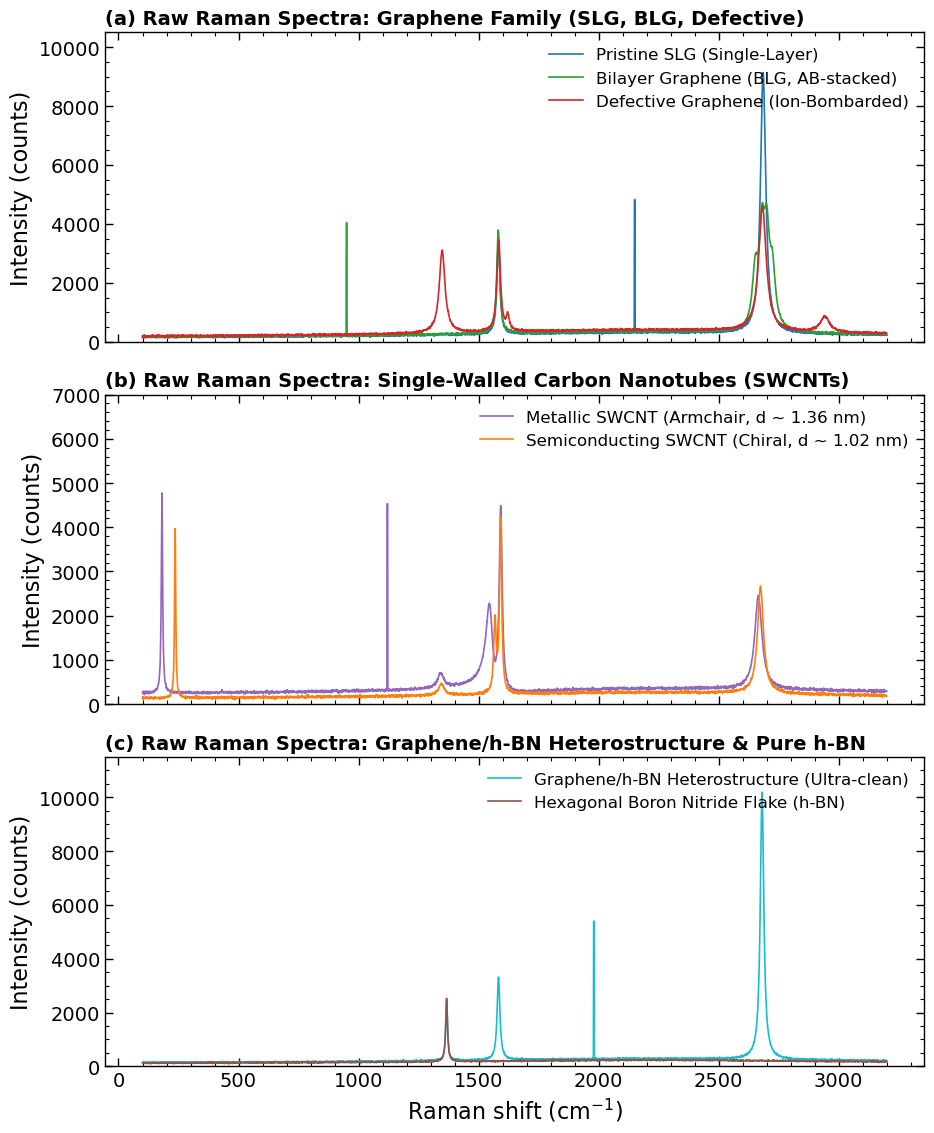

In [4]:
fig, axs = plt.subplots(3, 1, figsize=(9.5, 11.5), sharex=True)

# 1. Graphene Series
ax = axs[0]
for key, col, lbl in [
    ("graphene_pristine_532nm", COLORS["graphene"], "Pristine SLG (Single-Layer)"),
    ("graphene_bilayer_532nm", COLORS["graphene_bilayer"], "Bilayer Graphene (BLG, AB-stacked)"),
    ("graphene_defective_532nm", COLORS["graphene_defective"], "Defective Graphene (Ion-Bombarded)")
]:
    ax.plot(datasets[key]["wavenumber"], datasets[key]["intensity"], color=col, lw=1.2, label=lbl)
apply_axes_style(ax, xlabel="", ylabel="Intensity (counts)")
ax.set_title("(a) Raw Raman Spectra: Graphene Family (SLG, BLG, Defective)", loc="left", fontsize=14, fontweight="bold")
ax.legend(frameon=False, loc="upper right")
ax.set_ylim(0, 10500)

# 2. SWCNT Series
ax = axs[1]
for key, col, lbl in [
    ("cnt_swcnt_metallic_532nm", COLORS["swcnt_metallic"], "Metallic SWCNT (Armchair, d ~ 1.36 nm)"),
    ("cnt_swcnt_semiconducting_532nm", COLORS["swcnt_semiconducting"], "Semiconducting SWCNT (Chiral, d ~ 1.02 nm)")
]:
    ax.plot(datasets[key]["wavenumber"], datasets[key]["intensity"], color=col, lw=1.2, label=lbl)
apply_axes_style(ax, xlabel="", ylabel="Intensity (counts)")
ax.set_title("(b) Raw Raman Spectra: Single-Walled Carbon Nanotubes (SWCNTs)", loc="left", fontsize=14, fontweight="bold")
ax.legend(frameon=False, loc="upper right")
ax.set_ylim(0, 7000)

# 3. Heterostructure Series
ax = axs[2]
for key, col, lbl in [
    ("graphene_hbn_heterostructure_532nm", COLORS["graphene_hbn"], "Graphene/h-BN Heterostructure (Ultra-clean)"),
    ("hbn_pure_flake_532nm", COLORS["hbn_pure"], "Hexagonal Boron Nitride Flake (h-BN)")
]:
    ax.plot(datasets[key]["wavenumber"], datasets[key]["intensity"], color=col, lw=1.2, label=lbl)
apply_axes_style(ax, xlabel=r"Raman shift (cm$^{-1}$)", ylabel="Intensity (counts)")
ax.set_title("(c) Raw Raman Spectra: Graphene/h-BN Heterostructure & Pure h-BN", loc="left", fontsize=14, fontweight="bold")
ax.legend(frameon=False, loc="upper right")
ax.set_ylim(0, 11500)

save_publication_figure(fig, "raw_spectra_overview")
plt.show()

### 5. Kesimpulan Audit Dataset
1. Seluruh berkas spektral (7 berkas) berhasil diverifikasi integritasnya tanpa kegagalan checksum SHA-256.
2. Tidak ditemukan nilai kosong (NaN) maupun nilai tak hingga (Inf).
3. Sumbu bilangan gelombang bersifat monoton naik dengan interval seragam $\Delta\tilde{\nu} = 1.0\text{ cm}^{-1}$ pada rentang $100 - 3200\text{ cm}^{-1}$.
4. Terdapat noise latar belakang (luminesensi substrat SiO$_2$) dan spike cosmic-ray minor yang memerlukan pipeline preprocessing pada Notebook 02.